# Chapter 48: Credit, Default, Debt Overhang, and Agency

This notebook reruns four worked examples from the chapter: shareholders shifting risk onto creditors, debt overhang blocking a valuable project, equity priced as a call on the firm's assets, and a bank that rations credit instead of raising its rate. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def plus(value, digits=2, comma=True):
    """Number with an explicit sign for changes: '+0.42', '-0.20', '0.00'."""
    text = num(value, digits, comma)
    return text if text.startswith("-") or float(text.replace(",", "")) == 0 else f"+{text}"


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def norm_cdf(x):
    """Standard normal CDF N(x). black-scholes-merton-option-pricing (ch045): N(-0.1414) = 0.4438."""
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))


def risky_debt_split(payoffs, probs, face, escrow=0.0):
    """Expected enterprise, creditor and equity values of a plan with debt promising `face`.

    asset-substitution-risk-shifting (ch048): payoffs (160, 20), probs (0.55, 0.45), face 90 give
    enterprise 97, creditors 58.50, equity 38.50. With an escrow of 30 (returned on success, paid to
    creditors on failure, equity measured net of the deposit): equity 25, creditors 72.
    Escrow is paid to creditors only up to their shortfall in a state; any excess returns to equity.
    """
    if abs(sum(probs) - 1.0) > 1e-9:
        raise ValueError("probabilities must sum to one")
    ev = debt = eq = 0.0
    for v, p in zip(payoffs, probs):
        d = min(v, face)
        to_cred = min(escrow, face - d)
        debt += p * (d + to_cred)
        eq += p * (v - d - to_cred)
        ev += p * v
    return {"enterprise": float(ev), "debt": float(debt), "equity": float(eq)}


def waterfall(value, face):
    """Split terminal value between debt (paid first, up to face) and equity (residual).

    debt-overhang-underinvestment (ch048): value 105, face 95 gives (95, 10); value 70 gives (70, 0).
    """
    debt = min(max(value, 0.0), face)
    return float(debt), float(max(value - face, 0.0))


def overhang_private_npv(assets, face, invest, payoff):
    """Project NPV versus shareholders' private NPV under existing debt (zero discount rate).

    debt-overhang-underinvestment (ch048): assets 70, face 95, investment 24, payoff 35 give project
    NPV 11, equity with project 10, private NPV -14, creditor gain 25. Face 70 gives equity 35, private NPV 11.
    """
    d0, e0 = waterfall(assets, face)
    d1, e1 = waterfall(assets + payoff, face)
    return {"project_npv": float(payoff - invest), "equity_without": e0, "equity_with": e1,
            "debt_without": d0, "debt_with": d1, "private_npv": float(e1 - e0 - invest),
            "creditor_gain": float(d1 - d0), "invest": e1 - e0 - invest > 0}


def merton_equity(V, D, r, tau, sigma):
    """Merton equity as a call on assets: E = V N(d1) - D e^(-r tau) N(d2).

    merton-structural-default-model (ch048): V 150, D 120, r 0.03, tau 1, sigma 0.25 give d1 = 1.1376,
    d2 = 0.8876, E = 36.22, debt 113.78, risk-neutral default probability N(-d2) = 0.187.
    """
    d1 = (math.log(V / D) + (r + 0.5 * sigma ** 2) * tau) / (sigma * math.sqrt(tau))
    d2 = d1 - sigma * math.sqrt(tau)
    E = V * norm_cdf(d1) - D * math.exp(-r * tau) * norm_cdf(d2)
    return {"d1": d1, "d2": d2, "N_d1": norm_cdf(d1), "N_d2": norm_cdf(d2), "equity": E,
            "debt": V - E, "pd": norm_cdf(-d2)}


plt.rcParams.update(HOUSE_RC)


finance = SimpleNamespace(norm_cdf=norm_cdf, risky_debt_split=risky_debt_split, waterfall=waterfall, overhang_private_npv=overhang_private_npv, merton_equity=merton_equity)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'asset-substitution-risk-shifting': {'face': 90,
                                      'safe': 115,
                                      'high': 160,
                                      'low': 20,
                                      'p': 0.55,
                                      'escrow': 30,
                                      'ev_risky': 97,
                                      'debt_risky': 58.5,
                                      'equity_risky': 38.5,
                                      'equity_safe': 25,
                                      'debt_safe': 90,
                                      'value_lost': 18,
                                      'equity_gain': 13.5,
                                      'creditor_loss': 31.5,
                                      'equity_escrow': 25,
                                      'debt_escrow': 72},
 'debt-overhang-underinvestment': {'assets': 70,
                                   'face': 95,
                                   'invest': 24,
                                   'payoff': 35,
                                   'project_npv': 11,
                                   'equity_with': 10,
                                   'private_npv': -14,
                                   'creditor_gain': 25,
                                   'face_written_down': 70,
                                   'equity_written_down': 35,
                                   'private_npv_written_down': 11},
 'merton-structural-default-model': {'V': 150,
                                     'D': 120,
                                     'r': 0.03,
                                     'tau': 1,
                                     'sigma': 0.25,
                                     'd1': 1.138,
                                     'd2': 0.888,
                                     'N_d1': 0.87235,
                                     'N_d2': 0.81262,
                                     'equity': 36.22,
                                     'debt': 113.78,
                                     'pd': 0.187},
 'stiglitz-weiss-credit-rationing': {'loan': 12000,
                                     'rate_low': 0.07,
                                     'rate_high': 0.13,
                                     'repay_low': 12480,
                                     'repay_high': 12240,
                                     'repay_high_fixed': 12840,
                                     'return_low': 0.04,
                                     'return_high': 0.02,
                                     'return_fixed': 0.07,
                                     'promised_high': 13560,
                                     'funded': 80,
                                     'applicants': 140,
                                     'unfunded': 60},
 'constructed': {'asset-substitution-risk-shifting': {'p_values': [0.35, 0.45, 0.65], 'escrow': 50},
                 'debt-overhang-underinvestment': {'face': [80, 105], 'payoff': [30, 40]},
                 'merton-structural-default-model': {'V': [130, 170], 'sigma': [0.15, 0.35]}}}


def risk_shift_picture(p=0.55, escrow=0):
    q = 1 - p
    safe = finance.risky_debt_split((115,), (1.0,), 90)
    risky = finance.risky_debt_split((160, 20), (p, q), 90, escrow)
    to_cred = min(escrow, 70)
    gain = risky["equity"] - safe["equity"]
    fig, ax = new_figure()
    stacked_bar(ax, ["Safe plan", "Risky plan"], [[safe["debt"], risky["debt"]], [safe["equity"], risky["equity"]]],
                ["creditors' expected value", "equity's expected value"], colors=["navy", "gold"],
                ylabel="Expected value ($)", fmt=lambda v: num(v, 2))
    ax.set_ylim(min(0, risky["equity"]) - 15, 150)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Operating plan (debt promises $90)".replace("$", r"\$"))
    winner, tie = tie_or_winner("risky", risky["equity"], "safe", safe["equity"])
    if tie:
        pref = "Equity is indifferent between the plans: its private gain from risk is gone."
    elif winner == "risky":
        pref = f"Equity prefers the risky plan, gaining {num(gain, 2)} dollars."
    else:
        pref = f"Equity prefers the safe plan: the risky plan would cost it {num(-gain, 2)} dollars."
    lost = 115 - risky["enterprise"]
    esc_txt = (f" With an escrow of {escrow}, equity's payoff is measured net of the deposit: "
               f"{p}(70) + {num(q, 2)}({num(-escrow, 0)}) = {num(risky['equity'], 2)}.") if escrow else ""
    metrics = {"Risky plan enterprise value": num(risky["enterprise"], 2), "Safe plan enterprise value": "115.00",
               "Creditors, risky plan": num(risky["debt"], 2), "Equity, risky plan": num(risky["equity"], 2),
               "Equity, safe plan": "25.00", "Equity gain from switching": plus(gain, 2)}
    interp = (f"The risky plan is worth {p}(160) + {num(q, 2)}(20) = {num(risky['enterprise'], 2)}, which is "
              f"{num(lost, 2)} below the safe 115. Creditors expect {p}(90) + {num(q, 2)}(20 + {to_cred}) = "
              f"{num(risky['debt'], 2)} instead of 90.{esc_txt} Against 25 under the safe plan, {pref[0].lower() + pref[1:]}")
    steps = [f"Enterprise = {p}(160) + {num(q, 2)}(20) = {num(risky['enterprise'], 2)}",
             f"Creditors = {p}(90) + {num(q, 2)}(20 + {to_cred}) = {num(risky['debt'], 2)}",
             f"Equity = {p}(70) + {num(q, 2)}({num(-escrow, 0)}) = {num(risky['equity'], 2)}",
             f"Equity gain = {num(risky['equity'], 2)} - 25 = {plus(gain, 2)}",
             f"Value lost = 115 - {num(risky['enterprise'], 2)} = {num(lost, 2)}"]
    alt = (f"Stacked bars: safe plan creditors 90 and equity 25; risky plan with success probability {p} and escrow "
           f"{escrow}: creditors {num(risky['debt'], 2)} and equity {num(risky['equity'], 2)}, total "
           f"{num(risky['enterprise'], 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def overhang_picture(face=95, payoff=35):
    r = finance.overhang_private_npv(70, face, 24, payoff)
    total = 70 + payoff
    fig, ax = new_figure()
    stacked_bar(ax, ["Reject project", "Invest 24"], [[r["debt_without"], r["debt_with"]],
                                                       [r["equity_without"], r["equity_with"]]],
                ["creditors' payoff", "equity's payoff"], colors=["navy", "gold"],
                ylabel="Terminal payoff ($)", fmt=lambda v: num(v, 0))
    hline(ax, face, f"debt face {face}", col="terracotta", x_frac=0.02)
    ax.set_ylim(0, 135)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Shareholders' choice")
    winner, tie = tie_or_winner("invest", r["private_npv"], "reject", 0)
    if tie:
        verdict = "Shareholders are indifferent: the project just repays their contribution."
    elif winner == "invest":
        verdict = "Shareholders invest, because their private NPV is positive."
    else:
        verdict = (f"Shareholders reject a project worth {num(r['project_npv'], 0)} to the firm, because "
                   f"creditors capture {num(r['creditor_gain'], 0)} of the {payoff} dollar payoff.")
    metrics = {"Project NPV": num(r["project_npv"], 0), "Equity payoff with project": num(r["equity_with"], 0),
               "Equity private NPV": num(r["private_npv"], 0), "Creditor gain": num(r["creditor_gain"], 0),
               "Shareholders invest": "indifferent" if tie else ("yes" if winner == "invest" else "no")}
    interp = (f"The project's NPV is {payoff} - 24 = {num(r['project_npv'], 0)}. With it, assets are 70 + {payoff} = "
              f"{total}; debt takes min({total}, {face}) = {num(r['debt_with'], 0)} and equity gets "
              f"{num(r['equity_with'], 0)}. Without it, equity gets {num(r['equity_without'], 0)}. Equity's private "
              f"NPV is {num(r['equity_with'], 0)} - {num(r['equity_without'], 0)} - 24 = {num(r['private_npv'], 0)}. "
              f"{verdict}")
    steps = [f"Project NPV = {payoff} - 24 = {num(r['project_npv'], 0)}",
             f"Equity without = max(70 - {face}, 0) = {num(r['equity_without'], 0)}",
             f"Equity with = max({total} - {face}, 0) = {num(r['equity_with'], 0)}",
             f"Private NPV = {num(r['equity_with'], 0)} - {num(r['equity_without'], 0)} - 24 = "
             f"{num(r['private_npv'], 0)}",
             f"Creditor gain = {num(r['debt_with'], 0)} - {num(r['debt_without'], 0)} = {num(r['creditor_gain'], 0)}"]
    alt = (f"Bars of terminal payoff with debt face {face}: rejecting gives creditors {num(r['debt_without'], 0)} and "
           f"equity {num(r['equity_without'], 0)}; investing gives creditors {num(r['debt_with'], 0)} and equity "
           f"{num(r['equity_with'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def merton_picture(assets=150, sigma=0.25):
    V = assets
    D, r = 120, 0.03
    m = finance.merton_equity(V, D, r, 1, sigma)
    ln_ratio = math.log(V / D)
    drift = r + 0.5 * sigma ** 2
    pv_d = D * math.exp(-r)
    t1, t2 = V * m["N_d1"], pv_d * m["N_d2"]
    vt = np.linspace(1, 320, 600)
    mu = math.log(V) + r - 0.5 * sigma ** 2
    dens = np.exp(-(np.log(vt) - mu) ** 2 / (2 * sigma ** 2)) / (vt * sigma * math.sqrt(2 * math.pi))
    scale = 120 / dens.max()
    fig, ax = new_figure()
    ax.plot(vt, np.maximum(vt - D, 0), color=PALETTE["navy"], linewidth=2.2, label="equity payoff max(V - 120, 0)")
    ax.plot(vt, dens * scale, color=PALETTE["teal"], linewidth=1.6, label="risk-neutral density of V (scaled)")
    below = vt <= D
    ax.fill_between(vt[below], 0, (dens * scale)[below], color=PALETTE["terracotta"], alpha=0.35)
    vline(ax, D, "debt promise 120", col="terracotta", y_frac=0.68)
    label(ax, 30, 15, f"default probability {pct(m['pd'], 1)}", col="terracotta", dx=0, dy=0)
    ax.set_xlim(0, 320)
    ax.set_ylim(0, 210)
    ax.legend(loc="upper left", bbox_to_anchor=(0.43, 1.0), frameon=False)
    ax.set_xlabel("Asset value at year end V")
    ax.set_ylabel("Payoff ($)")
    metrics = {"d1": num(m["d1"], 3), "d2": num(m["d2"], 3), "N(d1)": num(m["N_d1"], 5),
               "N(d2)": num(m["N_d2"], 5), "Equity value": num(m["equity"], 2), "Debt value": num(m["debt"], 2),
               "Risk-neutral default probability": pct(m["pd"], 1)}
    interp = (f"With V = {V} and sigma = {sigma}, d1 = (ln({V}/120) + (0.03 + 0.5({sigma})^2))/{sigma} = "
              f"{num(m['d1'], 4)} and d2 = {num(m['d1'], 4)} - {sigma} = {num(m['d2'], 4)}. Equity is "
              f"{V}({num(m['N_d1'], 5)}) - 120e^(-0.03)({num(m['N_d2'], 5)}) = {num(m['equity'], 2)}, so debt is "
              f"{V} - {num(m['equity'], 2)} = {num(m['debt'], 2)}. The chance that assets end below 120 under the "
              f"pricing measure is N(-{num(m['d2'], 3)}) = {pct(m['pd'], 1)}; it is a pricing probability, not a "
              f"forecast.")
    steps = [f"ln({V}/120) = {num(ln_ratio, 5)}",
             f"0.03 + 0.5({sigma})^2 = {num(drift, 5)}",
             f"d1 = ({num(ln_ratio, 5)} + {num(drift, 5)}) / {sigma} = {num(m['d1'], 4)}",
             f"d2 = {num(m['d1'], 4)} - {sigma} = {num(m['d2'], 4)}",
             f"E = {V} x {num(m['N_d1'], 6)} - {num(pv_d, 4)} x {num(m['N_d2'], 6)} = {num(t1, 4)} - "
             f"{num(t2, 4)} = {num(m['equity'], 4)}",
             f"Debt = {V} - {num(m['equity'], 2)} = {num(m['debt'], 2)}",
             f"Default probability = N(-{num(m['d2'], 4)}) = {num(m['pd'], 4)}"]
    alt = (f"Equity payoff hockey stick with a kink at 120 and the risk-neutral density of year-end assets "
           f"centred near {V}; the shaded area below 120 is {pct(m['pd'], 1)}. Equity is worth {num(m['equity'], 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def lender_return(loan, repayment):
    """Bank's expected gross return per loan: (expected repayment - loan) / loan (stiglitz-weiss-credit-rationing)."""
    return (repayment - loan) / loan


def rationing_picture(repay13=12240, rate=0.13):
    loan = 12_000
    r7, r13 = lender_return(loan, 12_480), lender_return(loan, repay13)
    shown_repay = 12_480 if rate == 0.07 else repay13
    shown_ret = r7 if rate == 0.07 else r13
    promised = loan * (1 + rate)
    fig, ax = new_figure()
    ax.plot([7, 13], [100 * r7, 100 * r13], color=PALETTE["navy"], linewidth=2, marker="o")
    mark(ax, 7, 100 * r7, f"7%: return {pct(r7, 0)}", col="gold" if rate == 0.07 else "ink", dx=8, dy=8)
    mark(ax, 13, 100 * r13, f"13%: return {pct(r13, 0)}", col="gold" if rate == 0.13 else "ink", dx=-8, dy=8,
         ha="right")
    ax.set_xlim(5, 15)
    ax.set_ylim(0, 9)
    ax.set_xlabel("Quoted loan rate (%)")
    ax.set_ylabel("Bank's expected return (%)")
    winner, tie = tie_or_winner("7 percent", r7, "13 percent", r13)
    if tie:
        choice = "The two quotes give the same expected return, so the bank is indifferent."
    elif winner == "7 percent":
        choice = ("The bank prefers the 7 percent quote and rations credit: 80 loans for 140 applicants, though "
                  "applicants would promise 13 percent.")
    else:
        choice = "The bank prefers the 13 percent quote: the higher yield outweighs any loss in repayment."
    metrics = {"Return at 7 percent": pct(r7, 0), "Return at 13 percent": pct(r13, 0),
               "Quoted rate shown": pct(rate, 0), "Promised repayment at quote": num(promised, 0),
               "Expected repayment at quote": num(shown_repay, 0), "Bank prefers": "indifferent" if tie else winner}
    interp = (f"At the {pct(rate, 0)} quote a performing loan promises 12,000(1 + {rate}) = {num(promised, 0)}, but "
              f"the bank expects {num(shown_repay, 0)}, a return of ({num(shown_repay, 0)} - 12,000)/12,000 = "
              f"{pct(shown_ret, 0)}. The 7 percent quote returns (12,480 - 12,000)/12,000 = {pct(r7, 0)} and the "
              f"13 percent quote returns ({num(repay13, 0)} - 12,000)/12,000 = {pct(r13, 0)}. {choice}")
    steps = [f"Return at 7% = (12,480 - 12,000) / 12,000 = {num(r7, 2)} = {pct(r7, 0)}",
             f"Return at 13% = ({num(repay13, 0)} - 12,000) / 12,000 = {num(r13, 2)} = {pct(r13, 0)}",
             f"Promised at {pct(rate, 0)} = 12,000 x {num(1 + rate, 2)} = {num(promised, 0)}"]
    alt = (f"Two points of the bank's expected return: {pct(r7, 0)} at a 7 percent quote and {pct(r13, 0)} at "
           f"13 percent, when expected repayment at 13 percent is {num(repay13, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Asset-substitution risk shifting: gambling with creditors' money

Debt promises \$90. The safe plan pays \$115; the risky plan pays \$160 with probability 0.55 and \$20 otherwise:

$$0.55(160)+0.45(20)=97\text{ dollars}$$

$$0.55(160-90)+0.45(0)=38.50\text{ dollars}$$

With a \$30 escrow paid to creditors on failure:

$$0.55(70)+0.45(-30)=25\text{ dollars}$$

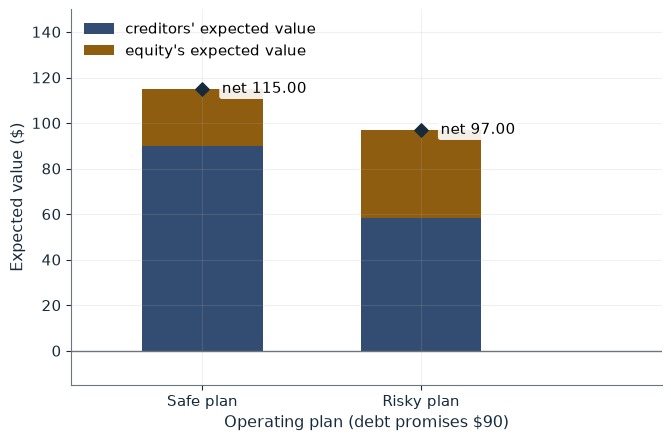

Risky plan enterprise value  97.00
Safe plan enterprise value   115.00
Creditors, risky plan        58.50
Equity, risky plan           38.50
Equity, safe plan            25.00
Equity gain from switching   +13.50

Worked steps:
  1. Enterprise = 0.55(160) + 0.45(20) = 97.00
  2. Creditors = 0.55(90) + 0.45(20 + 0) = 58.50
  3. Equity = 0.55(70) + 0.45(0) = 38.50
  4. Equity gain = 38.50 - 25 = +13.50
  5. Value lost = 115 - 97.00 = 18.00

The risky plan is worth 0.55(160) + 0.45(20) = 97.00, which is 18.00 below the safe 115. Creditors expect 0.55(90) + 0.45(20 + 0) = 58.50 instead of 90. Against 25 under the safe plan, equity prefers the risky plan, gaining 13.50 dollars.


In [2]:
show(risk_shift_picture(p=0.55, escrow=0))

Change one input, `escrow`, and hold the others at the book's values:

In [3]:
sweep(risk_shift_picture, 'escrow', [0, 30, 50], {'p': 0.55}, ['Equity, risky plan', 'Creditors, risky plan', 'Equity gain from switching'])

escrow | Equity, risky plan | Creditors, risky plan | Equity gain from switching
0 | 38.50 | 58.50 | +13.50
30 | 25.00 | 72.00 | 0.00
50 | 16.00 | 81.00 | -9.00


Without escrow equity gains 13.50 by choosing a plan that destroys 18 of value. A \$30 escrow leaves equity indifferent (25 against 25); \$50 makes the risky plan worse for equity.

## 2. Debt-overhang underinvestment

Assets pay \$70, debt promises \$95, the project costs \$24 and pays \$35:

$$35-24=11\text{ dollars}$$

$$10-24=-14\text{ dollars}$$

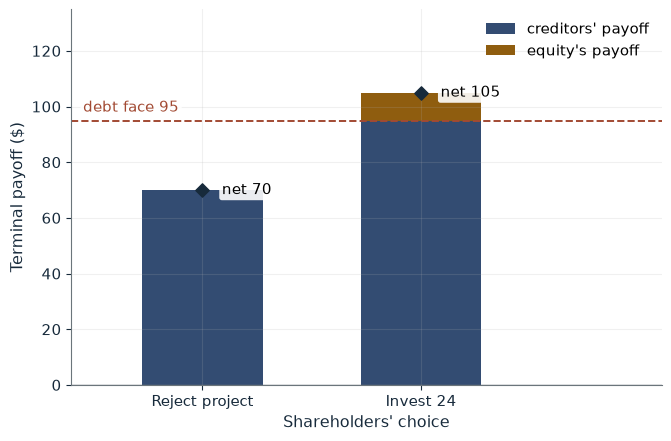

Project NPV                 11
Equity payoff with project  10
Equity private NPV          -14
Creditor gain               25
Shareholders invest         no

Worked steps:
  1. Project NPV = 35 - 24 = 11
  2. Equity without = max(70 - 95, 0) = 0
  3. Equity with = max(105 - 95, 0) = 10
  4. Private NPV = 10 - 0 - 24 = -14
  5. Creditor gain = 95 - 70 = 25

The project's NPV is 35 - 24 = 11. With it, assets are 70 + 35 = 105; debt takes min(105, 95) = 95 and equity gets 10. Without it, equity gets 0. Equity's private NPV is 10 - 0 - 24 = -14. Shareholders reject a project worth 11 to the firm, because creditors capture 25 of the 35 dollar payoff.


In [4]:
show(overhang_picture(face=95, payoff=35))

Change one input, `face`, and hold the others at the book's values:

In [5]:
sweep(overhang_picture, 'face', [70, 80, 95, 105], {'payoff': 35}, ['Equity payoff with project', 'Equity private NPV', 'Shareholders invest'])

face | Equity payoff with project | Equity private NPV | Shareholders invest
70 | 35 | 11 | yes
80 | 25 | 1 | yes
95 | 10 | -14 | no
105 | 0 | -24 | no


The project is worth 11 to the firm at every face value, but shareholders invest only when the face is 80 or less. Writing the debt down to 70 gives equity 105 - 70 = 35 and a private NPV of 11.

## 3. Merton structural default model

$$E_t=V_tN(d_1)-De^{-r\tau}N(d_2)$$

With $V=150$, $D=120$, $r=0.03$, $\tau=1$, $\sigma_V=0.25$:

$$d_1=\frac{\ln(150/120)+(0.03+0.5(0.25)^2)}{0.25}\approx1.138$$

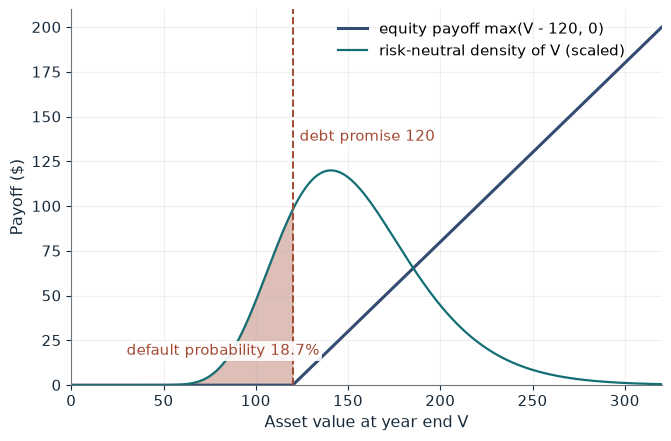

d1                                1.138
d2                                0.888
N(d1)                             0.87235
N(d2)                             0.81262
Equity value                      36.22
Debt value                        113.78
Risk-neutral default probability  18.7%

Worked steps:
  1. ln(150/120) = 0.22314
  2. 0.03 + 0.5(0.25)^2 = 0.06125
  3. d1 = (0.22314 + 0.06125) / 0.25 = 1.1376
  4. d2 = 1.1376 - 0.25 = 0.8876
  5. E = 150 x 0.872351 - 116.4535 x 0.812615 = 130.8526 - 94.6318 = 36.2208
  6. Debt = 150 - 36.22 = 113.78
  7. Default probability = N(-0.8876) = 0.1874

With V = 150 and sigma = 0.25, d1 = (ln(150/120) + (0.03 + 0.5(0.25)^2))/0.25 = 1.1376 and d2 = 1.1376 - 0.25 = 0.8876. Equity is 150(0.87235) - 120e^(-0.03)(0.81262) = 36.22, so debt is 150 - 36.22 = 113.78. The chance that assets end below 120 under the pricing measure is N(-0.888) = 18.7%; it is a pricing probability, not a forecast.


In [6]:
show(merton_picture(assets=150, sigma=0.25))

Change one input, `sigma`, and hold the others at the book's values:

In [7]:
sweep(merton_picture, 'sigma', [0.15, 0.25, 0.35], {'assets': 150}, ['Equity value', 'Debt value', 'Risk-neutral default probability'])

sigma | Equity value | Debt value | Risk-neutral default probability
0.15 | 33.92 | 116.08 | 5.3%
0.25 | 36.22 | 113.78 | 18.7%
0.35 | 39.84 | 110.16 | 29.2%


Equity is 36.22 and debt 113.78, with an 18.7 percent risk-neutral default probability. Higher volatility moves value from debt to equity without changing assets.

## 4. Stiglitz-Weiss credit rationing

$$\frac{12{,}480-12{,}000}{12{,}000}=0.04=4\%$$

$$\frac{12{,}240-12{,}000}{12{,}000}=0.02=2\%$$

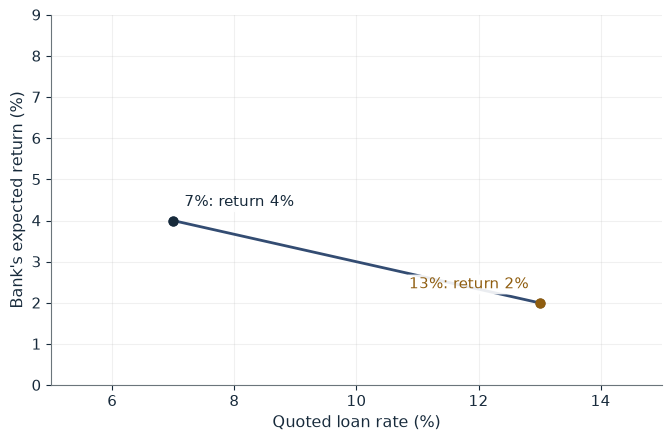

Return at 7 percent          4%
Return at 13 percent         2%
Quoted rate shown            13%
Promised repayment at quote  13,560
Expected repayment at quote  12,240
Bank prefers                 7 percent

Worked steps:
  1. Return at 7% = (12,480 - 12,000) / 12,000 = 0.04 = 4%
  2. Return at 13% = (12,240 - 12,000) / 12,000 = 0.02 = 2%
  3. Promised at 13% = 12,000 x 1.13 = 13,560

At the 13% quote a performing loan promises 12,000(1 + 0.13) = 13,560, but the bank expects 12,240, a return of (12,240 - 12,000)/12,000 = 2%. The 7 percent quote returns (12,480 - 12,000)/12,000 = 4% and the 13 percent quote returns (12,240 - 12,000)/12,000 = 2%. The bank prefers the 7 percent quote and rations credit: 80 loans for 140 applicants, though applicants would promise 13 percent.


In [8]:
show(rationing_picture(repay13=12240, rate=0.13))

Change one input, `repay13`, and hold the others at the book's values:

In [9]:
sweep(rationing_picture, 'repay13', [12240, 12480, 12840], {'rate': 0.13}, ['Return at 7 percent', 'Return at 13 percent', 'Bank prefers'])

repay13 | Return at 7 percent | Return at 13 percent | Bank prefers
12240 | 4% | 2% | 7 percent
12480 | 4% | 4% | indifferent
12840 | 4% | 7% | 13 percent


When adverse selection cuts expected repayment at 13 percent to 12,240, the bank earns 2 percent instead of 4 and keeps the 7 percent quote, rationing 80 loans among 140 applicants. With composition fixed (12,840) it would prefer 13 percent.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

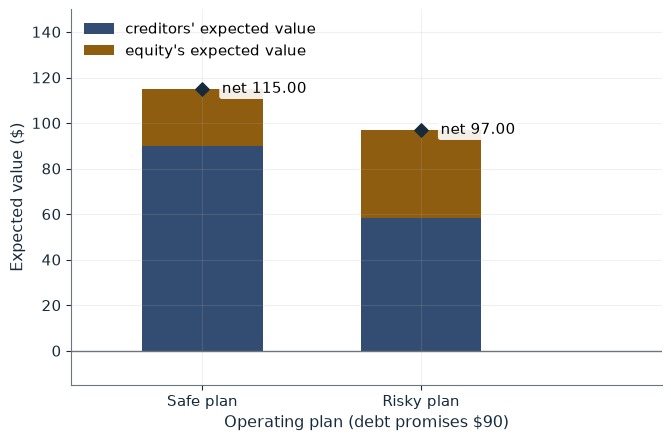

Risky plan enterprise value  97.00
Safe plan enterprise value   115.00
Creditors, risky plan        58.50
Equity, risky plan           38.50
Equity, safe plan            25.00
Equity gain from switching   +13.50

Worked steps:
  1. Enterprise = 0.55(160) + 0.45(20) = 97.00
  2. Creditors = 0.55(90) + 0.45(20 + 0) = 58.50
  3. Equity = 0.55(70) + 0.45(0) = 38.50
  4. Equity gain = 38.50 - 25 = +13.50
  5. Value lost = 115 - 97.00 = 18.00

The risky plan is worth 0.55(160) + 0.45(20) = 97.00, which is 18.00 below the safe 115. Creditors expect 0.55(90) + 0.45(20 + 0) = 58.50 instead of 90. Against 25 under the safe plan, equity prefers the risky plan, gaining 13.50 dollars.


In [10]:
show(risk_shift_picture(p=0.55, escrow=0))

## Practice

**1.** With success probability 0.45 and no escrow, does equity still prefer the risky plan?

<details><summary>Answer</summary>

Enterprise = 0.45(160) + 0.55(20) = 83; equity = 0.45(70) = 31.50 > 25, so yes, while the firm loses 32.

</details>

**2.** With debt face 80 and payoff 35, do shareholders invest?

<details><summary>Answer</summary>

Equity gets 105 - 80 = 25; private NPV = 25 - 24 = 1 > 0, so yes.

</details>

**3.** At V = 150 and sigma = 0.35, what are equity, debt and the default probability?

<details><summary>Answer</summary>

d1 = 0.898, d2 = 0.548; E = 39.84, debt = 110.16, N(-0.548) = 29.2%.

</details>